# 3. Logarithmic growth

**Model:** $y(t) = a + b\,\ln t$, for $t>0$

- $b>0$: $y$ keeps rising but ever more slowly (**diminishing returns**).
- Multiplying $t$ by a factor $k$ always **adds** the same amount: $y(kt) - y(t) = b \ln k$.
- It is the mirror image of the exponential: if $y = a + b\ln t$ then $t = e^{(y-a)/b}$. In the exponential model *adding* to $t$ *multiplies* $N$; here *multiplying* $t$ *adds* to $y$.
- On a graph whose horizontal axis is logarithmic, the model is a straight line.

**Why it matters.** The logarithm appears in two roles in Grade 11: as a growth model with diminishing returns, and as the tool that linearises exponential data. The literature notes that the logarithm is much less studied than the exponential, and that covariational approaches (arithmetic versus geometric progressions) may help students (Ferrari; Trejo, Ferrari & Martínez, 2021).

All data here is **simulated**; the true parameters are known.

**Contents**
1. The model and its parameters
2. The signature: equal ratios in $t$ give equal increments in $y$
3. Simulated example A: a learning curve (practice hours and test score)
4. Simulated example B: sound level in decibels
5. The logarithm as a tool: linearising exponential data
6. Simulation: how many observations do we need?
7. Using your own data
8. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
rng = np.random.default_rng(2026)

## 1. The model and its parameters

Left: ordinary axes (rapid early rise, then flattening). Right: logarithmic horizontal axis, where every curve is a straight line with slope $b$.

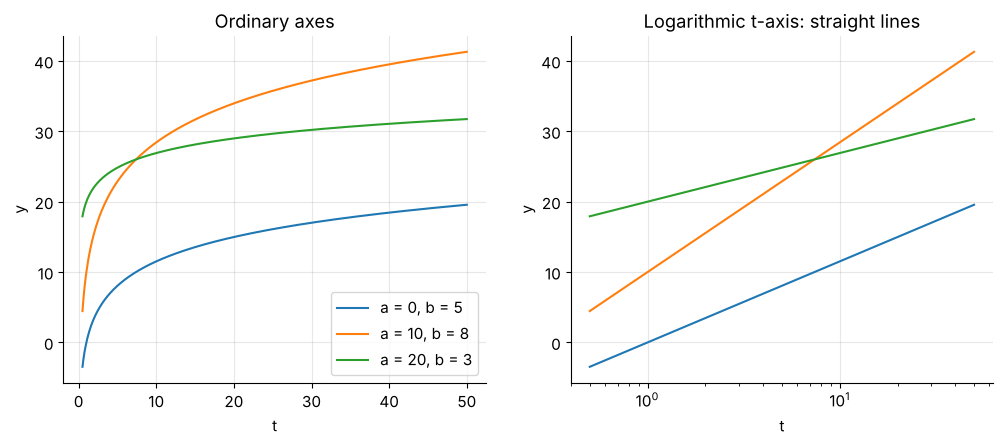

In [2]:
def log_model(t, a, b):
    return a + b * np.log(t)

t = np.linspace(0.5, 50, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for a, b in [(0, 5), (10, 8), (20, 3)]:
    for ax in axes:
        ax.plot(t, log_model(t, a, b), label=f"a = {a}, b = {b}")
axes[0].set_title("Ordinary axes")
axes[1].set_title("Logarithmic t-axis: straight lines")
axes[1].set_xscale("log")
for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel("y")
axes[0].legend()
plt.show()

## 2. The signature: equal ratios in $t$ give equal increments in $y$

In [3]:
a_demo, b_demo = 10, 8
t_geo = np.array([1, 2, 4, 8, 16, 32])        # t doubles each time
y_geo = log_model(t_geo, a_demo, b_demo)
print("t          :", t_geo)
print("y          :", np.round(y_geo, 2))
print("Δy         :", np.round(np.diff(y_geo), 3), " <- constant: each doubling of t adds the same")
print(f"b · ln 2   : {b_demo * np.log(2):.3f}")

t          : [ 1  2  4  8 16 32]
y          : [10.   15.55 21.09 26.64 32.18 37.73]
Δy         : [5.545 5.545 5.545 5.545 5.545]  <- constant: each doubling of t adds the same
b · ln 2   : 5.545


## 3. Simulated example A: a learning curve

A student's test score rises with hours of practice: $\text{score} = 30 + 12\ln(\text{hours})$, with noise (standard deviation 3 points). Early hours bring large gains, later hours bring small gains. We recover $a$ and $b$ by regressing the score on $\ln(\text{hours})$.

In [4]:
true_a, true_b, sigma = 30.0, 12.0, 3.0
hours = np.sort(rng.uniform(1, 40, size=30))
score = log_model(hours, true_a, true_b) + rng.normal(0, sigma, hours.size)

fit = stats.linregress(np.log(hours), score)
tcrit = stats.t.ppf(0.975, df=hours.size - 2)

print(f"Estimated a = {fit.intercept:5.2f}   (true {true_a})")
print(f"Estimated b = {fit.slope:5.2f}   (true {true_b})")
print(f"95% interval for b: {fit.slope - tcrit * fit.stderr:.2f} to {fit.slope + tcrit * fit.stderr:.2f}")
print(f"R² = {fit.rvalue ** 2:.4f}")

Estimated a = 28.64   (true 30.0)
Estimated b = 12.97   (true 12.0)
95% interval for b: 11.06 to 14.88
R² = 0.8731


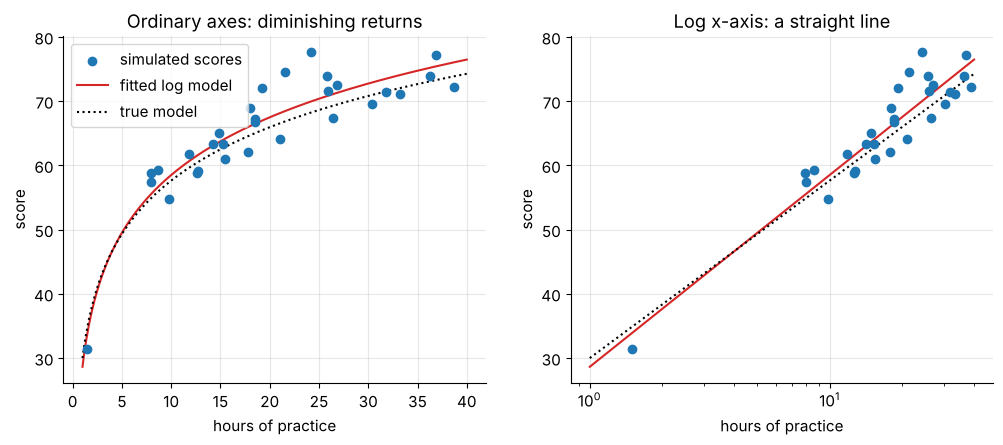

In [5]:
h_fine = np.linspace(1, 40, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in axes:
    ax.scatter(hours, score, color="tab:blue", label="simulated scores", zorder=3)
    ax.plot(h_fine, log_model(h_fine, fit.intercept, fit.slope), color="tab:red", label="fitted log model")
    ax.plot(h_fine, log_model(h_fine, true_a, true_b), "k:", label="true model")
    ax.set_xlabel("hours of practice")
    ax.set_ylabel("score")
axes[0].set_title("Ordinary axes: diminishing returns")
axes[1].set_title("Log x-axis: a straight line")
axes[1].set_xscale("log")
axes[0].legend()
plt.show()

In [6]:
# How many practice hours for a score of 85? Solve a + b ln t = 85  ->  t = exp((85 - a) / b)
target = 85
hours_hat = np.exp((target - fit.intercept) / fit.slope)
hours_true = np.exp((target - true_a) / true_b)
print(f"Hours needed for a score of {target}: estimated {hours_hat:.0f}, true model {hours_true:.0f}")
print(f"Each doubling of practice time adds about {fit.slope * np.log(2):.1f} points")

Hours needed for a score of 85: estimated 77, true model 98
Each doubling of practice time adds about 9.0 points


Reaching a high target takes a very large number of hours: this is the practical meaning of diminishing returns. A *linear* model would badly underestimate the effort needed.

## 4. Simulated example B: sound level in decibels

The decibel scale is a logarithm of intensity: $L = 10 \log_{10}(I / I_0)$, with $I_0 = 10^{-12}$ W/m². Intensity spans many orders of magnitude, but the level stays in a manageable 0 to 140 range. We add a small measurement error.

Estimated slope b = 4.394   (theory: 10 / ln 10 = 4.343)


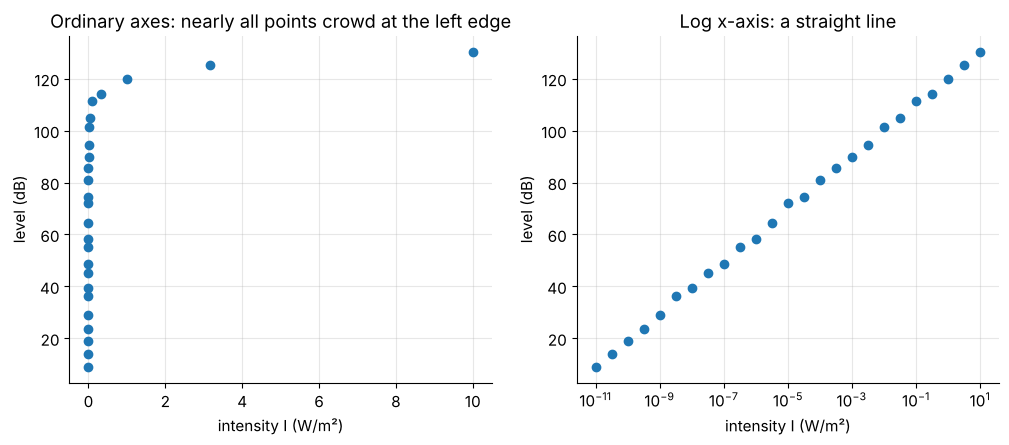

In [7]:
I0 = 1e-12
intensity = np.logspace(-11, 1, 25)                 # from 10^-11 to 10^1 W/m²
level_db = 10 * np.log10(intensity / I0) + rng.normal(0, 1.0, intensity.size)

# Regress dB on ln(I): slope should be 10/ln(10) ≈ 4.34
fit_db = stats.linregress(np.log(intensity), level_db)
print(f"Estimated slope b = {fit_db.slope:.3f}   (theory: 10 / ln 10 = {10 / np.log(10):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in axes:
    ax.scatter(intensity, level_db, color="tab:blue", zorder=3)
    ax.set_xlabel("intensity I (W/m²)")
    ax.set_ylabel("level (dB)")
axes[0].set_title("Ordinary axes: nearly all points crowd at the left edge")
axes[1].set_title("Log x-axis: a straight line")
axes[1].set_xscale("log")
plt.show()

## 5. The logarithm as a tool: linearising exponential data

Take the simulated bacteria data from the exponential notebook. On ordinary axes the curve is hard to judge; after taking $\ln$ of the counts it becomes a straight line whose slope is the growth rate $r$.

Slope of ln N against t = 0.01728  (true r = 0.01733)
Doubling time = ln 2 / slope = 40.1 min  (true 40.0)


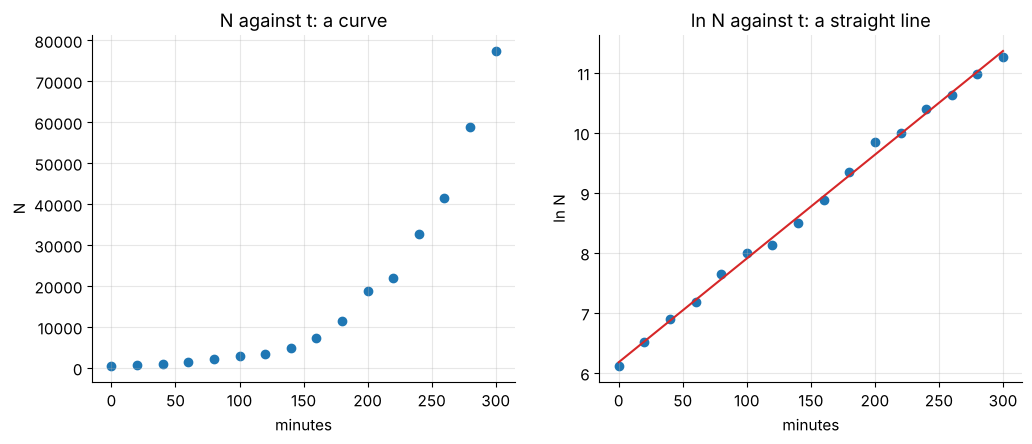

In [8]:
minutes = np.arange(0, 301, 20)
true_n0, true_r = 500.0, np.log(2) / 40.0
counts = true_n0 * np.exp(true_r * minutes) * np.exp(rng.normal(0, 0.08, minutes.size))

lin = stats.linregress(minutes, np.log(counts))
print(f"Slope of ln N against t = {lin.slope:.5f}  (true r = {true_r:.5f})")
print(f"Doubling time = ln 2 / slope = {np.log(2) / lin.slope:.1f} min  (true 40.0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(minutes, counts, color="tab:blue")
axes[0].set_xlabel("minutes")
axes[0].set_ylabel("N")
axes[0].set_title("N against t: a curve")
axes[1].scatter(minutes, np.log(counts), color="tab:blue")
axes[1].plot(minutes, lin.intercept + lin.slope * minutes, color="tab:red")
axes[1].set_xlabel("minutes")
axes[1].set_ylabel("ln N")
axes[1].set_title("ln N against t: a straight line")
plt.show()

## 6. Simulation: how many observations do we need?

We estimate $b$ from samples of different sizes, repeating each 1000 times. A larger sample reduces the spread of the estimate.

n =  5: mean b = 11.94, sd of b = 3.482
n = 10: mean b = 12.02, sd of b = 1.600
n = 20: mean b = 11.95, sd of b = 0.954
n = 40: mean b = 12.00, sd of b = 0.626
n = 80: mean b = 11.98, sd of b = 0.422


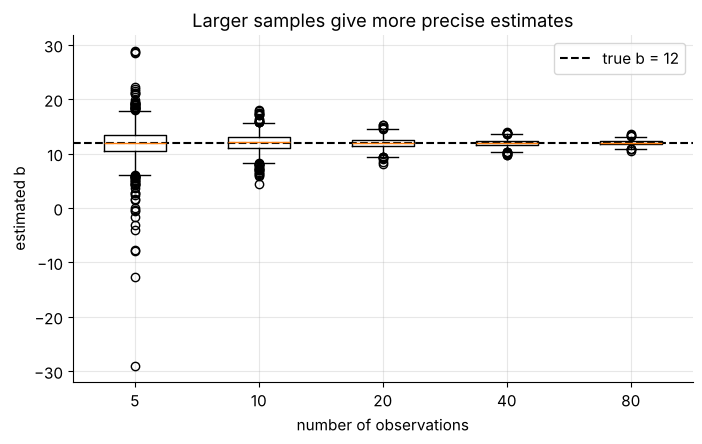

In [9]:
def estimate_b(n, sigma=3.0):
    h = rng.uniform(1, 40, size=n)
    s = log_model(h, true_a, true_b) + rng.normal(0, sigma, n)
    return stats.linregress(np.log(h), s).slope

sizes = [5, 10, 20, 40, 80]
results = {n: np.array([estimate_b(n) for _ in range(1000)]) for n in sizes}
for n, est in results.items():
    print(f"n = {n:>2}: mean b = {est.mean():5.2f}, sd of b = {est.std(ddof=1):.3f}")

fig, ax = plt.subplots()
ax.boxplot(list(results.values()), tick_labels=[str(n) for n in sizes])
ax.axhline(true_b, color="k", ls="--", label="true b = 12")
ax.set_xlabel("number of observations")
ax.set_ylabel("estimated b")
ax.set_title("Larger samples give more precise estimates")
ax.legend()
plt.show()

## 7. Using your own data

In [10]:
# import pandas as pd
# df = pd.read_csv("my_data.csv")                       # columns: t (> 0), y
# fit_own = stats.linregress(np.log(df["t"]), df["y"])
# print("a =", fit_own.intercept, " b =", fit_own.slope, " R² =", fit_own.rvalue ** 2)

## 8. Exercises

1. In section 3 change `true_b` to 5. How many hours are now needed for a score of 70? Compare with `true_b = 12`.
2. Show that $y(2t) - y(t) = b\ln 2$ for any $t$. Why does this mean "diminishing returns" in terms of *hours*?
3. Plot your own data with a logarithmic *x*-axis. Does it look like a straight line? What would a straight line on a logarithmic *y*-axis suggest instead?
4. Compare the logarithmic model with a linear model for the learning-curve data. Which has the smaller residuals? Does the answer depend on the range of hours?